<a href="https://colab.research.google.com/github/dhilaan12/nse-backtester/blob/main/nse-backtester.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install yfinance -q

import yfinance as yf

# NSE tickers need the .NS suffix
tickers = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS"]
data = yf.download(tickers, start="2020-01-01", auto_adjust=True)["Close"]

print(data.shape)
print(data.head())
print(data.isna().sum())

[*********************100%***********************]  3 of 3 completed

(1698, 3)
Ticker      HDFCBANK.NS  RELIANCE.NS       TCS.NS
Date                                             
2020-01-01   595.677246   672.216187  1821.426758
2020-01-02   599.474182   683.660217  1813.066162
2020-01-03   590.925171   684.484009  1849.198853
2020-01-06   578.136780   668.609314  1849.030518
2020-01-07   587.291321   678.895630  1853.568604
Ticker
HDFCBANK.NS    0
RELIANCE.NS    0
TCS.NS         0
dtype: int64


Buy & hold      2.578313
MA crossover    1.236757
Name: 2026-11-09 00:00:00, dtype: float64


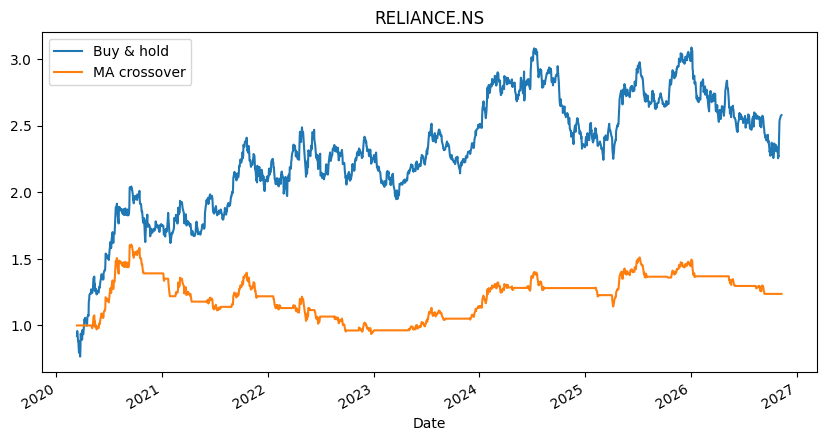

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

stock = "RELIANCE.NS"
price = data[stock]

fast = price.rolling(20).mean()
slow = price.rolling(50).mean()

# 1 = holding the stock, 0 = sitting in cash
signal = (fast > slow).astype(int)

# trade on the NEXT day's return, so we never use information we couldn't have had
daily_ret = price.pct_change()
strategy_ret = signal.shift(1) * daily_ret

# start once the slow average exists
valid = slow.notna()
growth = pd.DataFrame({
    "Buy & hold": (1 + daily_ret[valid]).cumprod(),
    "MA crossover": (1 + strategy_ret[valid]).cumprod(),
})

print(growth.iloc[-1])
growth.plot(figsize=(10, 5), title=stock)
plt.show()

In [ ]:
import numpy as np

def backtest(price, fast_w=20, slow_w=50, cost=0.002):
    fast = price.rolling(fast_w).mean()
    slow = price.rolling(slow_w).mean()
    signal = (fast > slow).astype(int)
    ret = price.pct_change()
    trades = signal.diff().abs().fillna(0)          # 1 whenever we buy or sell
    strat = signal.shift(1) * ret - trades.shift(1) * cost
    valid = slow.notna()
    return ret[valid], strat[valid]

def metrics(r):
    growth = (1 + r).cumprod()
    years = len(r) / 252
    return pd.Series({
        "Final value": growth.iloc[-1],
        "CAGR": growth.iloc[-1] ** (1 / years) - 1,
        "Sharpe": r.mean() / r.std() * np.sqrt(252),
        "Max drawdown": (growth / growth.cummax() - 1).min(),
    })

rows = {}
for t in data.columns:
    bh, st = backtest(data[t].dropna())
    rows[(t, "Buy & hold")] = metrics(bh)
    rows[(t, "MA crossover")] = metrics(st)

print(pd.DataFrame(rows).T.round(3))

                          Final value   CAGR  Sharpe  Max drawdown
HDFCBANK.NS Buy & hold          1.538  0.068   0.385        -0.317
            MA crossover        0.839 -0.027  -0.071        -0.491
RELIANCE.NS Buy & hold          2.578  0.156   0.662        -0.272
            MA crossover        1.128  0.019   0.193        -0.443
TCS.NS      Buy & hold          1.504  0.064   0.375        -0.534
            MA crossover        1.012  0.002   0.094        -0.419


In [ ]:
train_end = "2023-12-31"
grid = [(f, s) for f in (10, 20, 30) for s in (50, 100, 150, 200)]

def sharpe(r):
    return r.mean() / r.std() * np.sqrt(252)

# 1) choose windows using ONLY training data (2020-2023)
scores = {}
for f, s in grid:
    sh = []
    for t in data.columns:
        _, st = backtest(data[t].dropna(), f, s)
        sh.append(sharpe(st.loc[:train_end]))
    scores[(f, s)] = np.mean(sh)

best = max(scores, key=scores.get)
print("Best windows on training data:", best)
print(pd.Series(scores).round(3))

# 2) test those windows on 2024 onwards
test_rows = {}
for t in data.columns:
    bh, st = backtest(data[t].dropna(), *best)
    test_rows[(t, "Buy & hold")] = metrics(bh.loc["2024-01-01":])
    test_rows[(t, "MA crossover")] = metrics(st.loc["2024-01-01":])
print(pd.DataFrame(test_rows).T.round(3))

Best windows on training data: (30, 100)
10  50     0.450
    100    0.443
    150    0.264
    200    0.217
20  50     0.192
    100    0.469
    150    0.363
    200    0.422
30  50     0.157
    100    0.516
    150    0.322
    200    0.424
dtype: float64
                          Final value   CAGR  Sharpe  Max drawdown
HDFCBANK.NS Buy & hold          0.975 -0.009   0.063        -0.317
            MA crossover        0.879 -0.045  -0.246        -0.177
RELIANCE.NS Buy & hold          1.037  0.013   0.170        -0.272
            MA crossover        1.030  0.011   0.145        -0.167
TCS.NS      Buy & hold          0.718 -0.112  -0.360        -0.534
            MA crossover        0.720 -0.111  -0.814        -0.367


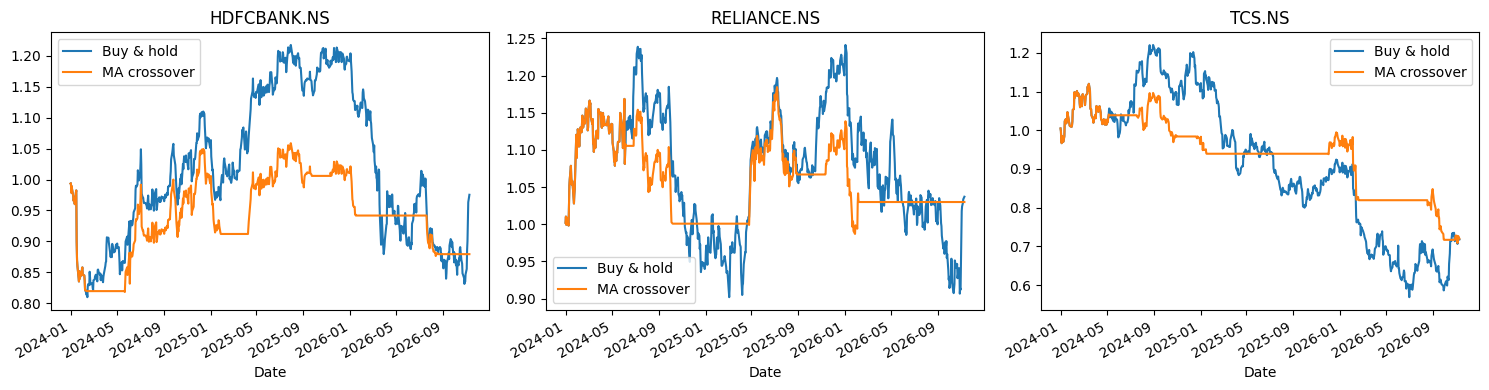

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, data.columns):
    bh, st = backtest(data[t].dropna(), *best)
    g = pd.DataFrame({
        "Buy & hold": (1 + bh.loc["2024-01-01":]).cumprod(),
        "MA crossover": (1 + st.loc["2024-01-01":]).cumprod(),
    })
    g.plot(ax=ax, title=t)
plt.tight_layout()
plt.savefig("test_period_results.png", dpi=150)
plt.show()